# 04 — Multivariate Forecasting
Test whether market and macroeconomic indicators improve on the univariate baseline. All predictors enter as lagged observations. We explicitly compare the Japan lithium carbonate import-price index included versus excluded.

In [22]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_FILE = Path("../../Data/lithium_consolidated_monthly.csv")
TARGET = "Selected lithium carbonate price (CNY/t)"
JAPAN_INDEX = "Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100"
RANDOM_STATE = 42

df = pd.read_csv(DATA_FILE)
df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").drop_duplicates("Month").set_index("Month").asfreq("MS")
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")


# Columns that should never be used as predictors
EXCLUDED = {
    TARGET,
    "Selected target source",
    "Lithium carbonate price (CNY/metric tonne)",
    "China spot lithium carbonate price (CNY/t) - CSV",
    "OLD - faulty cobalt settlement series (constant; excluded)",
    "China spot price open (CNY/t) - CSV",
    "China spot price high (CNY/t) - CSV",
    "China spot price low (CNY/t) - CSV",
    "China spot price volume (CSV)",
    "China spot price change (%) - CSV"
}

# Identify all remaining numeric candidate predictors
ALL_PREDICTORS = [
    c for c in df.select_dtypes(include=np.number).columns
    if c not in EXCLUDED
]

print("Total numeric candidate predictors:", len(ALL_PREDICTORS))


from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# All imputation/scaling is fitted inside each training fold.
def model_bank():
    return {
        "Linear Regression": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LinearRegression()
        ),
        "KNN": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            KNeighborsRegressor(n_neighbors=8, weights="distance")
        ),
        "SVR": make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            SVR(kernel="rbf", C=1.0, epsilon=0.1)
        ),
        "Random Forest": make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestRegressor(
                n_estimators=200, max_depth=4,
                min_samples_split=10, min_samples_leaf=5,
                max_features=0.7, random_state=RANDOM_STATE
            )
        ),
        "Gradient Boosting": make_pipeline(
            SimpleImputer(strategy="median"),
            GradientBoostingRegressor(
                n_estimators=100, learning_rate=0.03,
                max_depth=2, min_samples_leaf=5,
                subsample=0.8, loss="huber",
                random_state=RANDOM_STATE
            )
        ),
    }

PARAM_GRIDS = {
    "KNN": {
        "kneighborsregressor__n_neighbors": [5, 8, 12],
        "kneighborsregressor__weights": ["uniform", "distance"]
    },
    "SVR": {
        "svr__C": [0.1, 1.0, 10.0],
        "svr__epsilon": [0.1, 0.5, 1.0]
    },
    "Random Forest": {
        "randomforestregressor__max_depth": [3, 4, 5],
        "randomforestregressor__min_samples_leaf": [3, 5, 8]
    },
    "Gradient Boosting": {
        "gradientboostingregressor__n_estimators": [50, 100, 150],
        "gradientboostingregressor__learning_rate": [0.01, 0.03, 0.05],
        "gradientboostingregressor__max_depth": [1, 2, 3]
    }
}

def fit_with_time_series_cv(name, estimator, X_train, y_train):
    """Tune on chronological folds inside training data; never use the final test set."""
    if name not in PARAM_GRIDS:
        estimator.fit(X_train, y_train)
        return estimator, np.nan, {}
    cv = TimeSeriesSplit(n_splits=4)
    search = GridSearchCV(
        estimator=estimator,
        param_grid=PARAM_GRIDS[name],
        scoring="neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1,
        refit=True
    )
    search.fit(X_train, y_train)
    return search.best_estimator_, -search.best_score_, search.best_params_

def score_predictions(y_true, pred):
    return {
        "MAE": mean_absolute_error(y_true, pred),
        "RMSE": mean_squared_error(y_true, pred) ** 0.5,
        "R2": r2_score(y_true, pred)
    }


Total numeric candidate predictors: 19


## 1. Choose predictor sets

In [23]:
# Restrict to variables with at least 60 observed monthly values; the model pipeline handles remaining gaps.
coverage = df[ALL_PREDICTORS].notna().sum()
DUPLICATE_PREDICTORS = {
    "Japan lithium battery inventory (thousands)",
    "Japan lithium battery shipments (thousands)",
    "Japan lithium battery production (thousands)",
}
base_predictors = [
    c for c in ALL_PREDICTORS
    if coverage[c] >= 60 and c != JAPAN_INDEX and c not in DUPLICATE_PREDICTORS
]
with_japan = base_predictors + ([JAPAN_INDEX] if JAPAN_INDEX in ALL_PREDICTORS else [])
print("Base predictors:", len(base_predictors))
print("Japan index available:", JAPAN_INDEX in with_japan)
print("Japan index coverage:", df[JAPAN_INDEX].notna().sum() if JAPAN_INDEX in df else "not found")

Base predictors: 17
Japan index available: True
Japan index coverage: 201


## 2. Model benchmark (1, 3, 6, 12 months)

In [24]:

def make_supervised(horizon=1, n_lags=3, exog_cols=None):
    """
    Build multivariate forecasting features using historical data.

    Target-price lags: previous n_lags months.
    Exogenous predictors: previous n_lags months.
    """

    X = pd.DataFrame(index=df.index)

    # Historical lithium carbonate prices
    for lag in range(1, n_lags + 1):
        X[f"Target_lag_{lag}"] = df[TARGET].shift(lag)

    # Historical values of additional market predictors
    if exog_cols is not None:
        for col in exog_cols:
            for lag in range(1, n_lags + 1):
                X[f"{col}_lag_{lag}"] = df[col].shift(lag)

    # Align features with the future target
    y = df[TARGET].shift(-(horizon - 1))

    # Keep rows with an available target
    valid = y.notna()
    X = X.loc[valid]
    y = y.loc[valid]

    return X, y


def split_time(X, y, train_fraction=0.80):
    """Split observations chronologically without shuffling."""

    split_index = int(len(X) * train_fraction)

    X_train = X.iloc[:split_index]
    X_test = X.iloc[split_index:]

    y_train = y.iloc[:split_index]
    y_test = y.iloc[split_index:]

    return X_train, X_test, y_train, y_test


In [25]:
HORIZONS = [1, 3, 6, 12]
feature_sets = {"Multivariate — without Japan index": base_predictors,
                "Multivariate — with Japan index": with_japan}
results, predictions = [], {}
for set_name, cols in feature_sets.items():
    for h in HORIZONS:
        X, y = make_supervised(horizon=h, n_lags=3, exog_cols=cols)
        X_train, X_test, y_train, y_test = split_time(X, y)
        for name, model in model_bank().items():
            fitted_model, cv_rmse, best_params = fit_with_time_series_cv(
                name, model, X_train, y_train
            )
            pred = fitted_model.predict(X_test)
            results.append({
                "Feature set": set_name,
                "Horizon (months)": h,
                "Model": name,
                "CV RMSE": cv_rmse,
                "Best parameters": str(best_params),
                **score_predictions(y_test, pred)
            })
            predictions[(set_name, h, name)] = (y_test, pred)
results = pd.DataFrame(results).sort_values(["Horizon (months)", "Feature set", "RMSE"])
display(results)

,Feature set,Horizon (months),Model,CV RMSE,Best parameters,MAE,RMSE,R2
22,Multivariate — with Japan index,1,SVR,103243.938775,"{'svr__C': 10.0, 'svr__epsilon': 0.1}",75543.921297,94991.352619,-1.720415
24,Multivariate — with Japan index,1,Gradient Boosting,78682.899743,{'gradientboostingregressor__learning_rate': 0...,100926.937687,105184.126462,-2.335550
23,Multivariate — with Japan index,1,Random Forest,79442.906764,"{'randomforestregressor__max_depth': 4, 'rando...",112881.640924,116216.631671,-3.071961
20,Multivariate — with Japan index,1,Linear Regression,NaN,{},79076.746741,131606.627537,-4.221828
21,Multivariate — with Japan index,1,KNN,97803.521659,"{'kneighborsregressor__n_neighbors': 12, 'knei...",254412.882937,259253.894482,-19.263648
4,Multivariate — without Japan index,1,Gradient Boosting,78739.608730,{'gradientboostingregressor__learning_rate': 0...,63256.378916,76730.596425,-0.775024
2,Multivariate — without Japan index,1,SVR,103251.515024,"{'svr__C': 10.0, 'svr__epsilon': 1.0}",75543.877409,94991.109055,-1.720401
3,Multivariate — without Japan index,1,Random Forest,79123.397702,"{'randomforestregressor__max_depth': 4, 'rando...",127292.683000,130619.051364,-4.143753
0,Multivariate — without Japan index,1,Linear Regression,NaN,{},93006.049034,131508.431146,-4.214039
1,Multivariate — without Japan index,1,KNN,97014.130445,"{'kneighborsregressor__n_neighbors': 12, 'knei...",253249.490079,258017.805544,-19.070880


## 3. Does the Japan index help?

In [26]:
best_by_set = results.loc[results.groupby(["Feature set","Horizon (months)"])["RMSE"].idxmin()]
display(best_by_set.sort_values(["Horizon (months)","Feature set"]))
wide = best_by_set.pivot(index="Horizon (months)", columns="Feature set", values="RMSE")
wide["RMSE difference (with Japan - without Japan)"] = wide["Multivariate — with Japan index"] - wide["Multivariate — without Japan index"]
display(wide)

,Feature set,Horizon (months),Model,CV RMSE,Best parameters,MAE,RMSE,R2
22,Multivariate — with Japan index,1,SVR,103243.938775,"{'svr__C': 10.0, 'svr__epsilon': 0.1}",75543.921297,94991.352619,-1.720415
4,Multivariate — without Japan index,1,Gradient Boosting,78739.608730,{'gradientboostingregressor__learning_rate': 0...,63256.378916,76730.596425,-0.775024
27,Multivariate — with Japan index,3,SVR,103232.285899,"{'svr__C': 10.0, 'svr__epsilon': 0.1}",75050.194447,94599.211954,-1.698001
7,Multivariate — without Japan index,3,SVR,103242.042987,"{'svr__C': 10.0, 'svr__epsilon': 1.0}",75048.983737,94597.893106,-1.697926
34,Multivariate — with Japan index,6,Gradient Boosting,94851.644897,{'gradientboostingregressor__learning_rate': 0...,81797.950092,88472.154170,-1.525786
14,Multivariate — without Japan index,6,Gradient Boosting,94626.109648,{'gradientboostingregressor__learning_rate': 0...,78537.130389,85525.763564,-1.360354
39,Multivariate — with Japan index,12,Gradient Boosting,99622.928472,{'gradientboostingregressor__learning_rate': 0...,42216.119897,52112.000156,-0.155242
19,Multivariate — without Japan index,12,Gradient Boosting,100808.133152,{'gradientboostingregressor__learning_rate': 0...,47898.916383,54400.484712,-0.258935


Feature set,Multivariate — with Japan index,Multivariate — without Japan index,RMSE difference (with Japan - without Japan)
Horizon (months),,,
1,94991.352619,76730.596425,18260.756194
3,94599.211954,94597.893106,1.318848
6,88472.154170,85525.763564,2946.390606
12,52112.000156,54400.484712,-2288.484556


**How to interpret:** a lower RMSE with Japan means the index improved this particular chronological test comparison. It does not prove the index causes lithium carbonate price movements. Since the Japan index is a yen-denominated import-price index (not a direct spot quote), it is an auxiliary signal rather than an interchangeable target.

## 4. Plot best one-month-ahead multivariate model

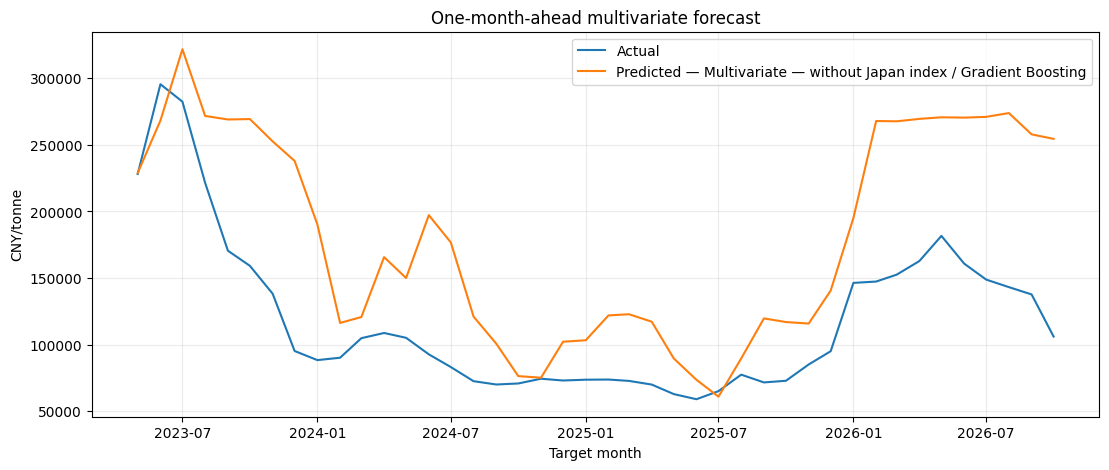

In [27]:
h=1
row = best_by_set[best_by_set["Horizon (months)"]==h].sort_values("RMSE").iloc[0]
key=(row["Feature set"], h, row["Model"])
y_test, pred=predictions[key]
fig, ax=plt.subplots(figsize=(13,5))
ax.plot(y_test.index,y_test.values,label="Actual")
ax.plot(y_test.index,pred,label=f"Predicted — {row['Feature set']} / {row['Model']}")
ax.set(title="One-month-ahead multivariate forecast",xlabel="Target month",ylabel="CNY/tonne")
ax.legend(); ax.grid(alpha=.25); plt.show()

## 5. Save results

In [28]:
results.to_csv("../../Results/multivariate_model_comparison.csv", index=False)
best_by_set.to_csv("../../Results/multivariate_best_by_feature_set.csv", index=False)
print("Saved multivariate results.")

Saved multivariate results.
